In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!rm -rf /content/work
!mkdir -p /content/work/outputs /content/work/models
!unzip -q /content/drive/MyDrive/PanVision/crops.zip -d /content/work/outputs
!unzip -q /content/drive/MyDrive/PanVision/code.zip -d /content/work
!cp /content/drive/MyDrive/PanVision/classifier.pt /content/work/models/classifier.pt
!pip install -q grad-cam
!ls /content/work /content/work/src/explainability

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
/content/work:
models	outputs  research  src

/content/work/src/explainability:
build_embeddings.py    gradcam_patient.py  retrieval_demo.py
crop_gradcam_scan.py   gradcam.py	   retrieval.py
demo_gradcam.py        model_loader.py	   slice_localisation.py
evaluate_retrieval.py  __pycache__	   standin_model.py
explain.py	       README.md	   view_scan.py


In [3]:
%cd /content/work
!python src/explainability/build_embeddings.py --model models/classifier.pt --crops outputs/crops

/content/work
Model from epoch 8 (validation AUC 0.9203671440105384), running on cuda
train: 32869 pictures from 1551 patients
val: 6818 pictures from 334 patients
test: 7004 pictures from 334 patients

Saved 2233 study fingerprints to outputs/embeddings.npz


In [4]:
!python src/explainability/slice_localisation.py --split val

98 PDAC studies in val with reference tumour slices
Share of the top-3 slices that are tumour slices: 0.59  (chance 0.37)
At least one of the top-3 is a tumour slice: 77% of studies
The first number should be clearly higher than chance.


In [6]:
import glob, os, numpy as np
pdac = healthy = None
for p in sorted(glob.glob('/content/work/outputs/crops/*.npz')):
    with np.load(p) as f:
        if str(f['split']) == 'val':
            if int(f['label']) == 1 and pdac is None and f['has_lesion'].any(): pdac = os.path.basename(p)[:-4]
            if int(f['label']) == 0 and healthy is None: healthy = os.path.basename(p)[:-4]
    if pdac and healthy: break
print(pdac, healthy)

100003_00001 100007_00001


Study 100003_00001 (val, true label PDAC)
Patient score 0.655  threshold 0.13  ->  PDAC
   slice 31: 1.00 | reference tumour slice
   slice 35: 1.00 | reference tumour slice
   slice 32: 1.00 | reference tumour slice
Saved outputs/gradcam_100003_00001.png
Study 100007_00001 (val, true label non-PDAC)
Patient score 0.251  threshold 0.13  ->  PDAC
   slice 130: 0.99
   slice 131: 0.89
   slice 128: 0.82
Saved outputs/gradcam_100007_00001.png


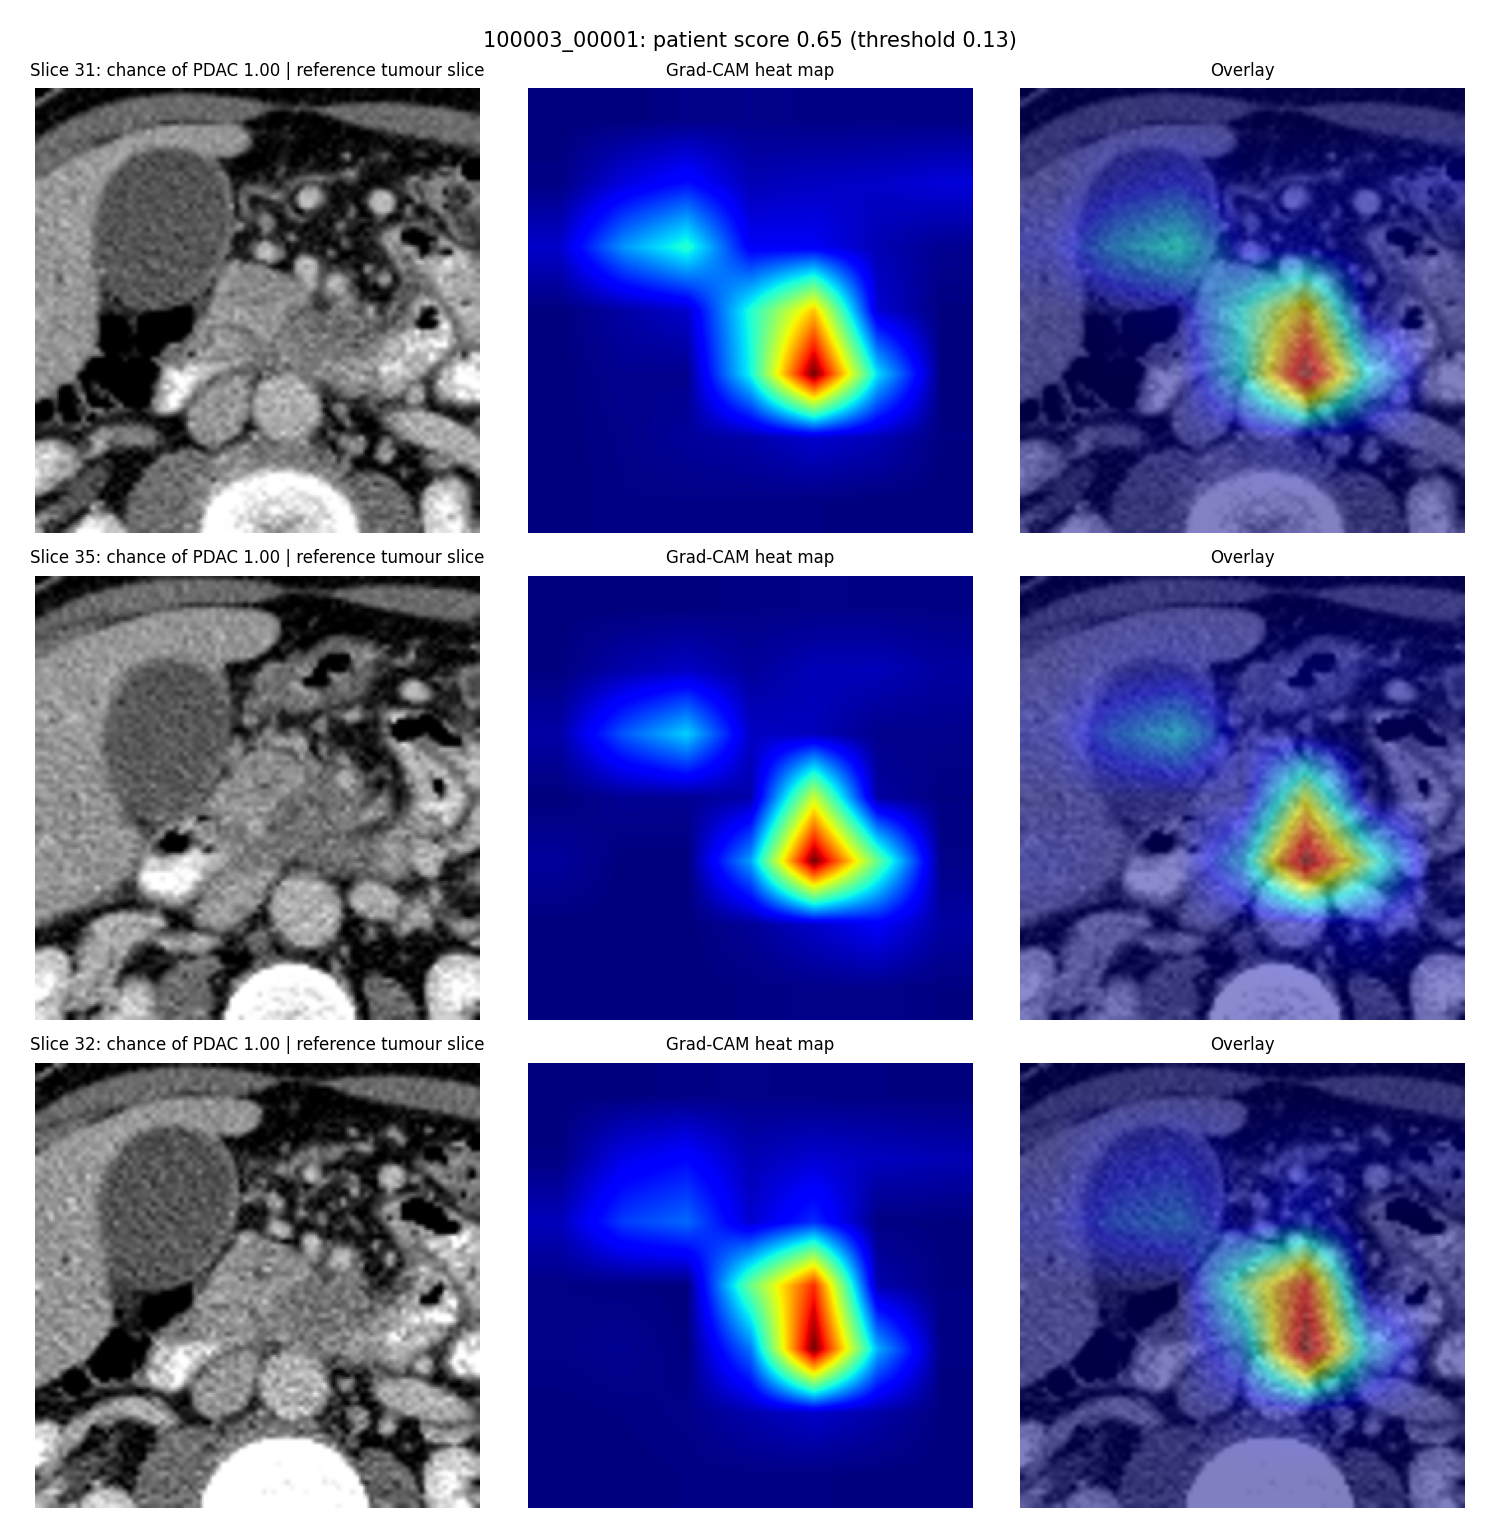

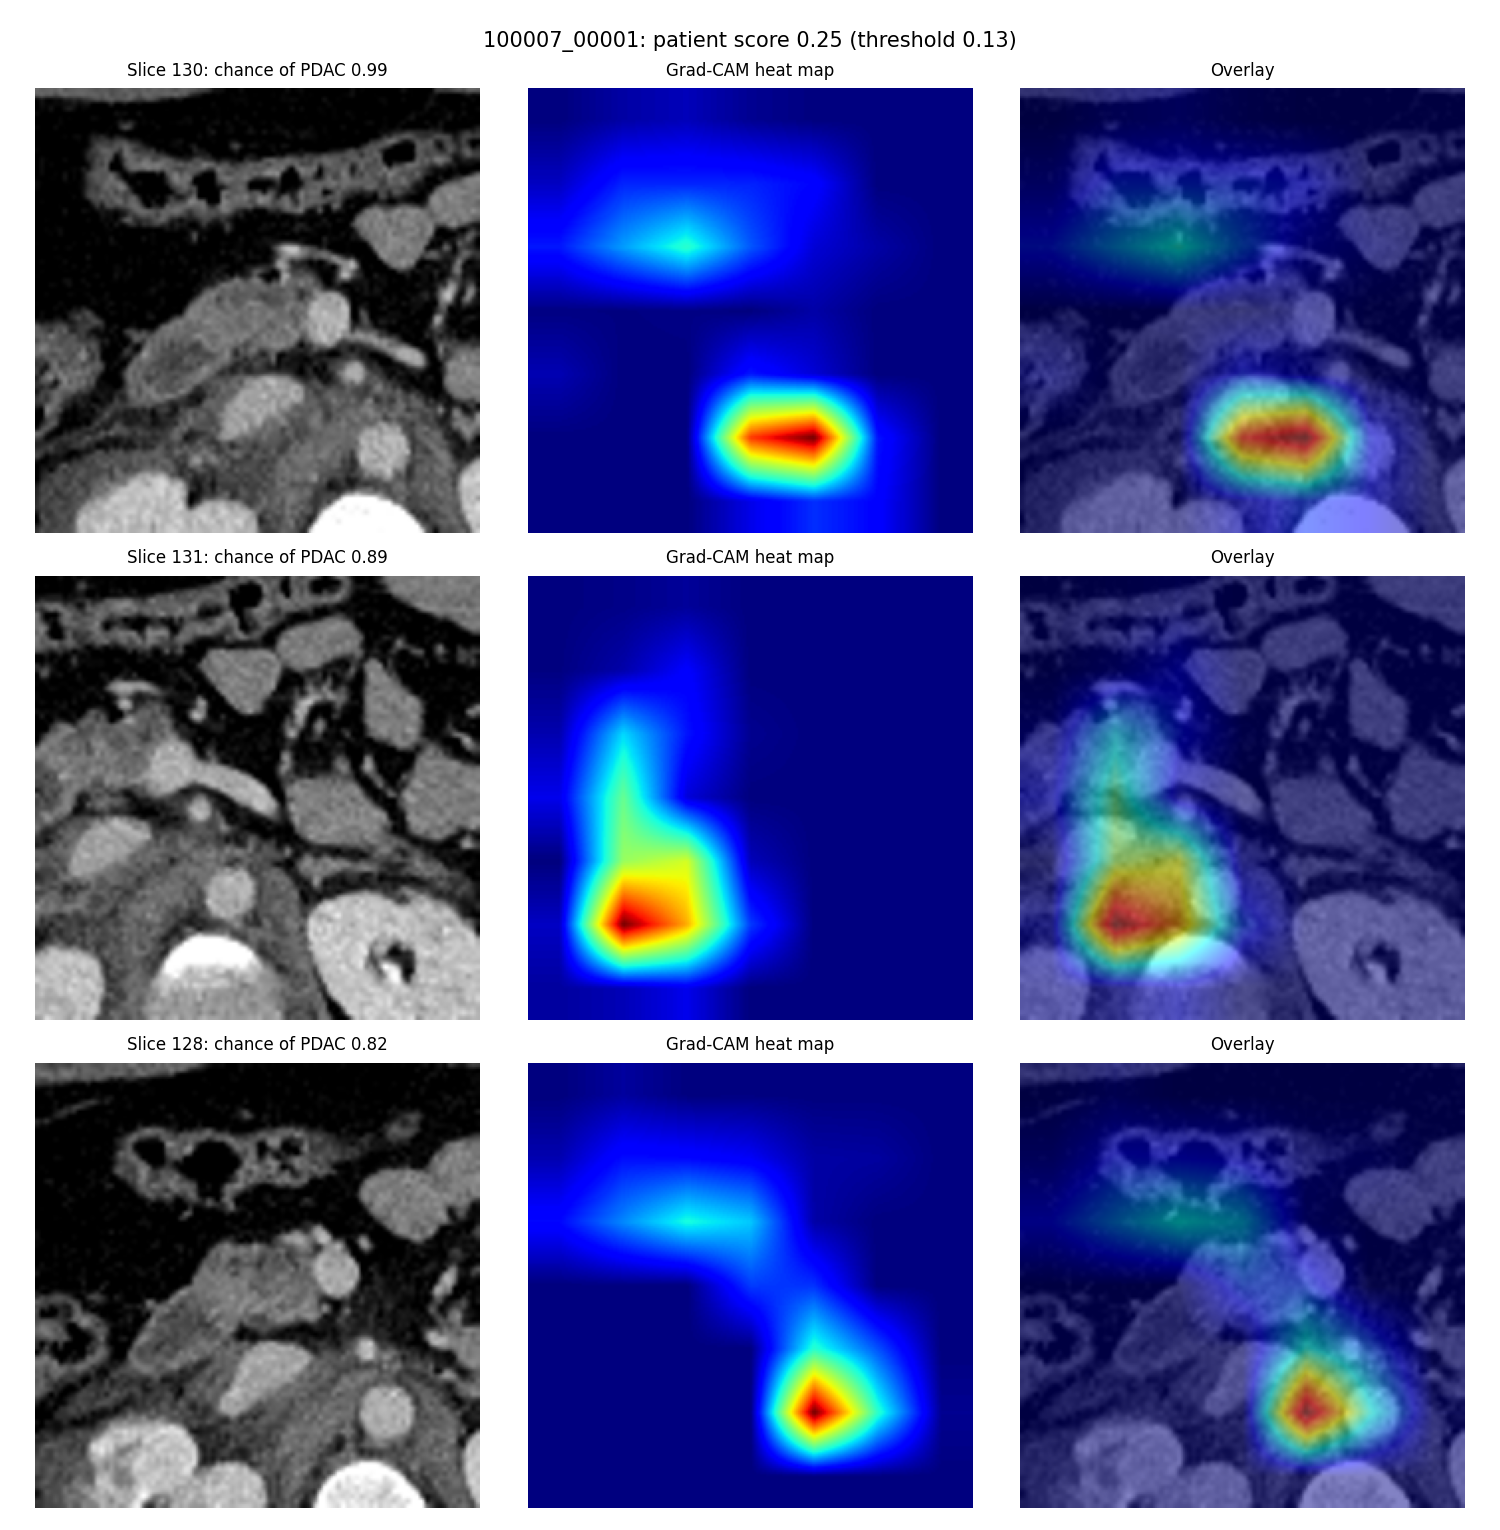

In [7]:
for s in (pdac, healthy):
    !python src/explainability/gradcam_patient.py {s} --model models/classifier.pt --crops outputs/crops
from IPython.display import Image, display
for s in (pdac, healthy):
    display(Image(f'outputs/gradcam_{s}.png'))

In [8]:
!cp outputs/embeddings.npz /content/drive/MyDrive/PanVision/embeddings_resnet50.npz
!cp outputs/gradcam_*.png /content/drive/MyDrive/PanVision/

In [9]:
!python src/explainability/evaluate_retrieval.py --split val

Database: 1551 training patients (469 PDAC)
Queries : 334 val patients (101 PDAC)

Precision@3, all queries : 0.86  (random baseline 0.58)
Precision@3, PDAC queries: 0.76  (random baseline 0.30)
At least one of the 3 has the same label: 90% of queries

A useful model must beat the random baseline, especially for PDAC queries.
